# Notebook 07 — Model Comparison and Final Results
Loads all saved models and evaluates on consistent test sets to produce the final comparison table.
> **Prerequisites:** Run notebooks 01-06 first.

## 1. Mount Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

Mounted at /content/drive


## 2. Unzip / Download Datasets (Skip if Already Done)

In [2]:
import zipfile, os

if not os.path.exists("/content/mri_data/MRI/Training/No Tumor/Tr-no_1.jpg"):
    with zipfile.ZipFile("/content/drive/MyDrive/MRI/MRI.zip", 'r') as z:
        z.extractall("/content/mri_data/")
    print("MRI unzipped!")
else:
    print("MRI already ready.")

if not os.path.exists("/content/ct_tumor/dataset/head ct/no"):
    from google.colab import files
    files.upload()
    os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
    os.system("cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json")
    os.makedirs("/content/ct_tumor", exist_ok=True)
    os.system("kaggle datasets download -d nipaanjum/head-ct-images-for-classification -p /content/ct_tumor/")
    os.system("unzip /content/ct_tumor/*.zip -d /content/ct_tumor/")
    print("CT downloaded!")
else:
    print("CT already ready.")

MRI unzipped!


Saving kaggle.json to kaggle.json
CT downloaded!


## 3. Imports

In [3]:
import numpy as np
import cv2
import random
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve
)
from sklearn.model_selection import train_test_split

IMG_SIZE   = (224, 224)
BATCH_SIZE = 16
print("Ready!")

Ready!


## 4. Load All Splits

In [4]:
mri_data = np.load('/content/drive/MyDrive/MRI/mri_splits.npz',     allow_pickle=True)
ct_data  = np.load('/content/drive/MyDrive/CT_Tumor/ct_splits.npz', allow_pickle=True)

# Unimodal test sets (used directly for MRI and CT baselines)
mri_test_paths = mri_data['test_paths'];  y_mri_test = mri_data['y_test']
ct_test_paths  = ct_data['test_paths'];   y_ct_test  = ct_data['y_test']

# All splits needed to reconstruct fusion test set correctly
mri_train_paths = mri_data['train_paths']; y_mri_train = mri_data['y_train']
mri_val_paths   = mri_data['val_paths'];   y_mri_val   = mri_data['y_val']
ct_train_paths  = ct_data['train_paths'];  y_ct_train  = ct_data['y_train']
ct_val_paths    = ct_data['val_paths'];    y_ct_val    = ct_data['y_val']

print(f'MRI test: {len(mri_test_paths)} | CT test: {len(ct_test_paths)}')


MRI test: 40 | CT test: 40


## 5. Load Test Images

In [5]:
def load_img(path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, IMG_SIZE)
    return np.expand_dims(img / 255.0, axis=-1)

print("Loading MRI test images...")
X_mri_test = np.array([load_img(p) for p in mri_test_paths])
print("Loading CT test images...")
X_ct_test  = np.array([load_img(p) for p in ct_test_paths])

print(f"X_mri_test: {X_mri_test.shape} | X_ct_test: {X_ct_test.shape}")

Loading MRI test images...
Loading CT test images...
X_mri_test: (40, 224, 224, 1) | X_ct_test: (40, 224, 224, 1)


## 6. Build Fusion Test Set (Paired from Test Split Only — No Leakage)


In [6]:
# Reproduce the EXACT same pairing logic used in NB05 and NB06,
# but applied ONLY to the test split — matching those notebooks exactly.

def pair_by_label(paths_a, labels_a, paths_b, labels_b, seed=42):
    import random as _r
    _r.seed(seed)
    a0 = [p for p,l in zip(paths_a, labels_a) if l==0]
    a1 = [p for p,l in zip(paths_a, labels_a) if l==1]
    b0 = [p for p,l in zip(paths_b, labels_b) if l==0]
    b1 = [p for p,l in zip(paths_b, labels_b) if l==1]
    _r.shuffle(a0); _r.shuffle(a1); _r.shuffle(b0); _r.shuffle(b1)
    n0 = min(len(a0), len(b0))
    n1 = min(len(a1), len(b1))
    return a0[:n0]+a1[:n1], b0[:n0]+b1[:n1], [0]*n0+[1]*n1

# Build the fusion test set from test-split paths only
test_mri_p, test_ct_p, test_fusion_labels = pair_by_label(
    mri_test_paths, y_mri_test, ct_test_paths, y_ct_test
)

X_mri_fusion_test = np.array([load_img(p) for p in test_mri_p])
X_ct_fusion_test  = np.array([load_img(p) for p in test_ct_p])
y_fusion_test     = np.array(test_fusion_labels)

print(f'Fusion test set: {len(y_fusion_test)} pairs | Class dist: {np.bincount(y_fusion_test)}')
print('NOTE: Unimodal models are evaluated on their own test sets (y_mri_test / y_ct_test).')
print('      Fusion models are evaluated on the paired fusion test set (y_fusion_test).')
print('      These are different sets by design — models require different input formats.')


Fusion test set: 40 pairs | Class dist: [20 20]
NOTE: Unimodal models are evaluated on their own test sets (y_mri_test / y_ct_test).
      Fusion models are evaluated on the paired fusion test set (y_fusion_test).
      These are different sets by design — models require different input formats.


## 7. Load All Saved Models

In [7]:
mri_model         = tf.keras.models.load_model('/content/drive/MyDrive/MRI/mri_baseline.keras')
ct_model          = tf.keras.models.load_model('/content/drive/MyDrive/CT_Tumor/ct_baseline.keras')
fusion_baseline   = tf.keras.models.load_model('/content/drive/MyDrive/CT_Tumor/fusion_baseline.keras')
fusion_cw         = tf.keras.models.load_model('/content/drive/MyDrive/CT_Tumor/confidence_weighted_fusion.keras')

print("All models loaded!")

All models loaded!


## 8. Evaluate All Models

In [8]:
def get_metrics(y_true, y_probs):
    y_pred = (y_probs > 0.5).astype(int)
    return {
        'Accuracy':  round(accuracy_score(y_true, y_pred), 4),
        'Precision': round(precision_score(y_true, y_pred, zero_division=0), 4),
        'Recall':    round(recall_score(y_true, y_pred, zero_division=0), 4),
        'F1-Score':  round(f1_score(y_true, y_pred, zero_division=0), 4),
        'ROC-AUC':   round(roc_auc_score(y_true, y_probs), 4)
    }

print("Evaluating MRI baseline...")
mri_probs   = mri_model.predict(X_mri_test, batch_size=BATCH_SIZE, verbose=0).flatten()
mri_metrics = get_metrics(y_mri_test, mri_probs)

print("Evaluating CT baseline...")
ct_probs    = ct_model.predict(X_ct_test, batch_size=BATCH_SIZE, verbose=0).flatten()
ct_metrics  = get_metrics(y_ct_test, ct_probs)

print("Evaluating fusion baseline...")
fb_probs    = fusion_baseline.predict([X_mri_fusion_test, X_ct_fusion_test], batch_size=BATCH_SIZE, verbose=0).flatten()
fb_metrics  = get_metrics(y_fusion_test, fb_probs)

print("Evaluating confidence-weighted fusion...")
cw_probs    = fusion_cw.predict([X_mri_fusion_test, X_ct_fusion_test], batch_size=BATCH_SIZE, verbose=0).flatten()
cw_metrics  = get_metrics(y_fusion_test, cw_probs)

print("Done!")

Evaluating MRI baseline...
Evaluating CT baseline...
Evaluating fusion baseline...


Evaluating confidence-weighted fusion...
Done!


## 9. Final Comparison Table

In [9]:
results = pd.DataFrame({
    'Model': [
        'MRI Baseline (CNN)',
        'CT Baseline (CNN)',
        'Fusion Baseline (Simple Concat)',
        'Confidence-Weighted Fusion (Proposed)'
    ],
    'Accuracy':  [mri_metrics['Accuracy'],  ct_metrics['Accuracy'],  fb_metrics['Accuracy'],  cw_metrics['Accuracy']],
    'Precision': [mri_metrics['Precision'], ct_metrics['Precision'], fb_metrics['Precision'], cw_metrics['Precision']],
    'Recall':    [mri_metrics['Recall'],    ct_metrics['Recall'],    fb_metrics['Recall'],    cw_metrics['Recall']],
    'F1-Score':  [mri_metrics['F1-Score'],  ct_metrics['F1-Score'],  fb_metrics['F1-Score'],  cw_metrics['F1-Score']],
    'ROC-AUC':   [mri_metrics['ROC-AUC'],   ct_metrics['ROC-AUC'],   fb_metrics['ROC-AUC'],   cw_metrics['ROC-AUC']]
})

print(results.to_string(index=False))

                                Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
                   MRI Baseline (CNN)     0.750     0.7273    0.80    0.7619   0.8200
                    CT Baseline (CNN)     0.750     1.0000    0.50    0.6667   0.8775
      Fusion Baseline (Simple Concat)     0.750     0.7273    0.80    0.7619   0.8250
Confidence-Weighted Fusion (Proposed)     0.775     0.7391    0.85    0.7907   0.8225


## 10. Comparison Bar Chart

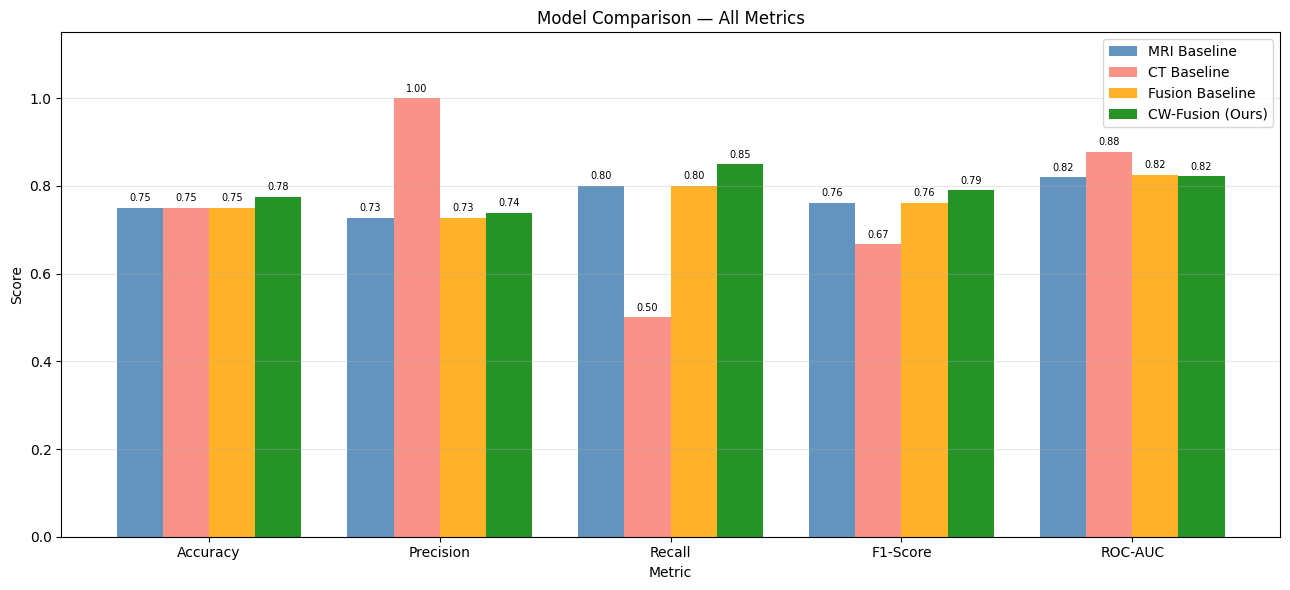

In [10]:
metrics_to_plot = ['Accuracy','Precision','Recall','F1-Score','ROC-AUC']
models  = ['MRI Baseline','CT Baseline','Fusion Baseline','CW-Fusion (Ours)']
colors  = ['steelblue','salmon','orange','green']
x       = np.arange(len(metrics_to_plot))
width   = 0.2

fig, ax = plt.subplots(figsize=(13,6))
for i, (model, metrics, color) in enumerate(zip(
    models,
    [mri_metrics, ct_metrics, fb_metrics, cw_metrics],
    colors
)):
    values = [metrics[m] for m in metrics_to_plot]
    bars = ax.bar(x + i*width, values, width, label=model, color=color, alpha=0.85)
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()+0.01,
                f'{val:.2f}', ha='center', va='bottom', fontsize=7)

ax.set_xlabel('Metric')
ax.set_ylabel('Score')
ax.set_title('Model Comparison — All Metrics')
ax.set_xticks(x + width*1.5)
ax.set_xticklabels(metrics_to_plot)
ax.set_ylim(0, 1.15)
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 11. ROC Curve Comparison

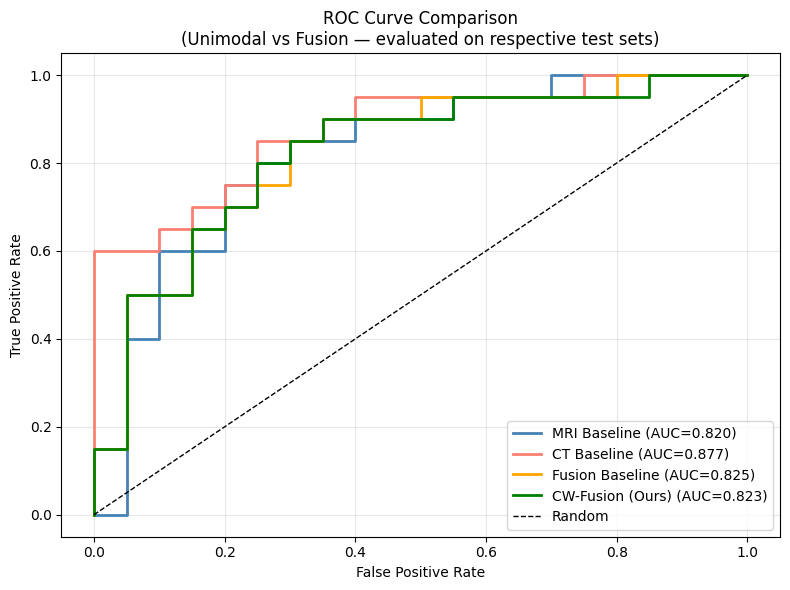

In [11]:
# Note: MRI and CT baselines are evaluated on their own modality test sets.
# Fusion models are evaluated on the paired fusion test set.
# These are different test sets by design (different input formats required).
# ROC curves are shown together for visual reference only.

plt.figure(figsize=(8,6))
for name, y_true, y_probs, color in [
    ('MRI Baseline',     y_mri_test,    mri_probs, 'steelblue'),
    ('CT Baseline',      y_ct_test,     ct_probs,  'salmon'),
    ('Fusion Baseline',  y_fusion_test, fb_probs,  'orange'),
    ('CW-Fusion (Ours)', y_fusion_test, cw_probs,  'green'),
]:
    fpr, tpr, _ = roc_curve(y_true, y_probs)
    auc = roc_auc_score(y_true, y_probs)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})', color=color, linewidth=2)

plt.plot([0,1],[0,1],'k--',linewidth=1,label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison\n(Unimodal vs Fusion — evaluated on respective test sets)')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 12. Save Results to Drive

In [12]:
results.to_csv('/content/drive/MyDrive/CT_Tumor/final_results.csv', index=False)
print("Results saved!")
print(results.to_string(index=False))

Results saved!
                                Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
                   MRI Baseline (CNN)     0.750     0.7273    0.80    0.7619   0.8200
                    CT Baseline (CNN)     0.750     1.0000    0.50    0.6667   0.8775
      Fusion Baseline (Simple Concat)     0.750     0.7273    0.80    0.7619   0.8250
Confidence-Weighted Fusion (Proposed)     0.775     0.7391    0.85    0.7907   0.8225
